# Neural Networks in PyTorch — Part 1
### Building & Training Models: From Healthyfi.me to a Hand-Written Training Loop

**Session length:** ~120 minutes

## 60-second warm-up — are we solid on the fundamentals?


Fire these one at a time:

1. "A layer takes 3 neurons in, feeding 5 neurons in the next layer. What's the shape of that weight matrix?"

   **EXPECTED RESPONSE:** 3×5
2. "Two paths in the computation graph both lead back to the same weight. How do you combine their gradients?"

   **EXPECTED RESPONSE:** add them — sum over paths, straight from the chain rule
3. "Sigmoid and tanh are the usual suspects behind vanishing gradients. Why?"

   **EXPECTED RESPONSE:** their derivative is close to 0 across most of the input range, so gradients shrink every time they get multiplied backward through a layer
4. "Can a neural network do regression?"

   **EXPECTED RESPONSE:** yes — keep the output layer's activation linear



## The business case: Healthyfi.me

You're a data scientist at Healthyfi.me. Customers are labelled **A / B / C / D**, based on the highest workout intensity they can safely handle.

**Task:** given a new customer's health metrics, predict their class so the app can recommend a customised workout plan.

This is the problem we'll solve today, end-to-end, in PyTorch — from raw data to a trained, evaluated neural network.

## Data acquisition

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

Let's pull the Healthyfi.me dataset.

In [ ]:
!wget "https://drive.google.com/uc?export=download&id=1GVhrh2rH6hUunV4Tf7lQoSFsqov9aPjU" -O healthyfime.csv
df = pd.read_csv("healthyfime.csv")
df.head()

--2026-10-01 10:42:26--  https://drive.google.com/uc?export=download&id=1GVhrh2rH6hUunV4Tf7lQoSFsqov9aPjU
Resolving drive.google.com (drive.google.com)... 172.253.147.100, 172.253.147.139, 172.253.147.102, ...
Connecting to drive.google.com (drive.google.com)|172.253.147.100|:443... connected.
HTTP request sent, awaiting response... 303 See Other
Location: https://drive.usercontent.google.com/download?id=1GVhrh2rH6hUunV4Tf7lQoSFsqov9aPjU&export=download [following]
--2026-10-01 10:42:26--  https://drive.usercontent.google.com/download?id=1GVhrh2rH6hUunV4Tf7lQoSFsqov9aPjU&export=download
Resolving drive.usercontent.google.com (drive.usercontent.google.com)... 192.178.239.132, 2607:f8b0:400c:c3f::84
Connecting to drive.usercontent.google.com (drive.usercontent.google.com)|192.178.239.132|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 761835 (744K) [application/octet-stream]
Saving to: ‘healthyfime.csv’

healthyfime.csv     100%[===================>] 743.98K  --

,age,gender,height_cm,weight_kg,body fat_%,diastolic,systolic,gripForce,sit and bend forward_cm,sit-ups counts,broad jump_cm,class
0,27.0,M,172.3,75.24,21.3,80.0,130.0,54.9,18.4,60.0,217.0,C
1,25.0,M,165.0,55.80,15.7,77.0,126.0,36.4,16.3,53.0,229.0,A
2,31.0,M,179.6,78.00,20.1,92.0,152.0,44.8,12.0,49.0,181.0,C
3,32.0,M,174.5,71.10,18.4,76.0,147.0,41.4,15.2,53.0,219.0,B
4,28.0,M,173.8,67.70,17.1,70.0,127.0,43.5,27.1,45.0,217.0,B


**Data description**

| Id | Feature | Description |
| :-- | :-- | :-- |
|01| **age** | age of the customer |
|02| **gender** | gender of the customer (M/F) |
|03| **height_cm** | height of the customer in cm |
|04| **weight_kg** | weight of the customer in kg |
|05| **body_fat_%** | % of fat in customer's body |
|06| **diastolic** | diastolic blood pressure |
|07| **systolic** | systolic blood pressure |
|08| **gripForce** | strength of customer's grip |
|09| **sit and bend forward_cm** | flexibility measure |
|10| **sit-ups counts** | count of sit-ups customer can perform |
|11| **broad jump_cm** | max jump the customer can perform, in cm |
|12| **class** | target — workout intensity category |

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13393 entries, 0 to 13392
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      13393 non-null  float64
 1   gender                   13393 non-null  object 
 2   height_cm                13393 non-null  float64
 3   weight_kg                13393 non-null  float64
 4   body fat_%               13393 non-null  float64
 5   diastolic                13393 non-null  float64
 6   systolic                 13393 non-null  float64
 7   gripForce                13393 non-null  float64
 8   sit and bend forward_cm  13393 non-null  float64
 9   sit-ups counts           13393 non-null  float64
 10  broad jump_cm            13393 non-null  float64
 11  class                    13393 non-null  object 
dtypes: float64(10), object(2)
memory usage: 1.2+ MB


---
### QUIZ 1

**Which observation from `df.info()` above is correct for this dataset?**

a) There are null values in the dataset.

b) All features are stored as numerical dtypes.

c) At least one feature (`gender`) is stored as a non-numerical (object) dtype.

d) The target variable `class` is already stored as an integer.

**Correct answer: c**

`gender` holds strings ('M'/'F') and `class` holds string labels ('A'–'D') at this point — both are object dtype, not yet encoded. There are no null values here, which rules out (a). This is exactly why we still have an encoding step ahead of us before any modeling.

---

## EDA & preprocessing

- `gender` has two levels → binary encode.
- `class` is ordinal → map to 0/1/2/3, so PyTorch can work with it directly.

In [ ]:
df.replace({"M": 0, "F": 1}, inplace=True)
df.head()

/tmp/ipykernel_1513/3197794122.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.replace({"M": 0, "F": 1}, inplace=True)


,age,gender,height_cm,weight_kg,body fat_%,diastolic,systolic,gripForce,sit and bend forward_cm,sit-ups counts,broad jump_cm,class
0,27.0,0,172.3,75.24,21.3,80.0,130.0,54.9,18.4,60.0,217.0,C
1,25.0,0,165.0,55.80,15.7,77.0,126.0,36.4,16.3,53.0,229.0,A
2,31.0,0,179.6,78.00,20.1,92.0,152.0,44.8,12.0,49.0,181.0,C
3,32.0,0,174.5,71.10,18.4,76.0,147.0,41.4,15.2,53.0,219.0,B
4,28.0,0,173.8,67.70,17.1,70.0,127.0,43.5,27.1,45.0,217.0,B


In [ ]:
classes = list(df['class'].unique())
mapping_dict = {ch: i for i, ch in enumerate(sorted(classes, reverse=True))}
print(mapping_dict)
df['class'].replace(mapping_dict, inplace=True)
df.head()

{'D': 0, 'C': 1, 'B': 2, 'A': 3}


/tmp/ipykernel_1513/2550660351.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['class'].replace(mapping_dict, inplace=True)
/tmp/ipykernel_1513/2550660351.py:4: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['class'].replace(mapping_dict, inplace=True)


,age,gender,height_cm,weight_kg,body fat_%,diastolic,systolic,gripForce,sit and bend forward_cm,sit-ups counts,broad jump_cm,class
0,27.0,0,172.3,75.24,21.3,80.0,130.0,54.9,18.4,60.0,217.0,1
1,25.0,0,165.0,55.80,15.7,77.0,126.0,36.4,16.3,53.0,229.0,3
2,31.0,0,179.6,78.00,20.1,92.0,152.0,44.8,12.0,49.0,181.0,1
3,32.0,0,174.5,71.10,18.4,76.0,147.0,41.4,15.2,53.0,219.0,2
4,28.0,0,173.8,67.70,17.1,70.0,127.0,43.5,27.1,45.0,217.0,2


Quick look at linear relationships and feature ranges before we scale anything:

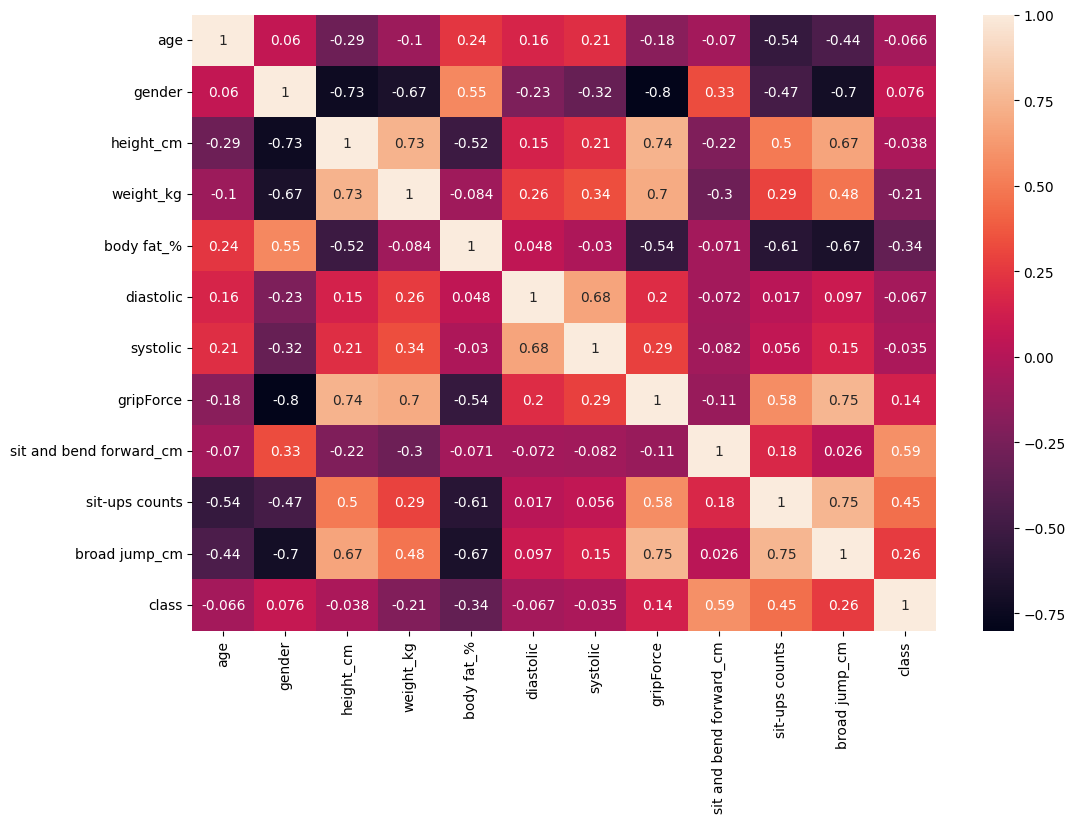

In [ ]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), annot=True)
plt.show()

No strong linear relationships with `class` — the boundary between classes is non-linear, which is exactly the kind of problem a neural net is suited for.

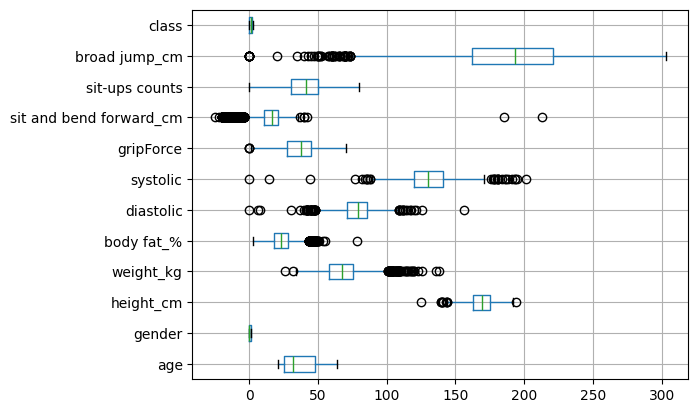

In [ ]:
df.boxplot(rot=0, vert=False)
plt.show()

Features are on very different scales, so we'll standardize.

In [ ]:
X, y = df.iloc[:, :-1], df.iloc[:, -1]
print(X.shape, y.shape)

(13393, 11) (13393,)


In [ ]:
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.1, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.1, random_state=42)

print('Train : ', X_train.shape, y_train.shape)
print('Valid : ', X_val.shape, y_val.shape)
print('Test  : ', X_test.shape, y_test.shape)

Train :  (10847, 11) (10847,)
Valid :  (1206, 11) (1206,)
Test  :  (1340, 11) (1340,)


In [ ]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

We now have clean, scaled, split data, ready to feed into a model. Let's meet the framework we'll build it in: **PyTorch**. One thing to get used to right away — PyTorch won't create a single weight for a layer until you tell it exactly what it needs to know: how many values come in, and how many go out. Let's see what that actually looks like.

## PyTorch, minute one: tensors & autograd (just enough to proceed)


- A **tensor** is PyTorch's array — same job as a NumPy array, but it can also track *how it was computed*.
- Every trainable weight in a PyTorch model is a tensor with `requires_grad=True`.
- Because PyTorch tracks the computation graph, it can work out `∂Loss/∂W` for *every* weight automatically — that's **autograd**, and it's the exact mechanism that did the chain rule for you in the NN-from-scratch class.

In [ ]:
import torch
print(torch.__version__)

x = torch.tensor([1.0, 2.0, 3.0], requires_grad=True)
y = (x ** 2).sum()
y.backward()
print(x.grad)   # dy/dx = 2x

2.11.0+cpu
tensor([2., 4., 6.])


That `x.grad` is `2x` — PyTorch just did the calculus for you. Every `.backward()` call you write for the rest of this module is this exact mechanism, just running on a much bigger graph.

**COMMON MISCONCEPTION:** "`requires_grad=True` means PyTorch trains the tensor." No — it means PyTorch *tracks* it so a gradient can be computed later, if `.backward()` is called. Actually updating the values still needs an optimizer, which we'll get to shortly.

## Building a layer: `nn.Linear`

**Question for chat:** a layer that takes our 11 features and produces 64 outputs needs a weight matrix connecting every input to every output. What information does PyTorch need from us before it can create that matrix?

**EXPECTED RESPONSE:** both the input size *and* the output size, stated up front — nothing is inferred automatically from the data.

In [ ]:
import torch.nn as nn

layer = nn.Linear(in_features=11, out_features=64)
print(layer.weight.shape, layer.bias.shape)

torch.Size([64, 11]) torch.Size([64])


`nn.Linear(11, 64)` creates a fully-connected layer with an 11×64 weight matrix and a 64-length bias vector, both created immediately — because we told it both sizes. Every `nn.Linear` layer in a network needs its `in_features` and `out_features` stated explicitly like this; there's no shortcut where a later layer infers its input size from whatever came before it.

**FOLLOW-UP:** "So what happens if layer 2's `in_features` doesn't match layer 1's `out_features`?" → a shape-mismatch error, but only the first time you actually run a forward pass — PyTorch doesn't check this when the layers are merely defined.

In [ ]:
model = nn.Sequential(
    nn.Linear(11, 64),
    nn.ReLU(),
    nn.Linear(64, 4)
)
print(model)

Sequential(
  (0): Linear(in_features=11, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=4, bias=True)
)


Notice the output layer has no activation attached. Same reasoning as the regression case in this morning's warm-up: raw scores (**logits**) come out, and whatever turns them into probabilities gets folded into the loss function instead of the model. Hold that thought — it's the seed of a bug we'll deliberately walk into in Part 2.

---
### QUIZ 2

**Which of these correctly builds a 2-layer PyTorch network for our 11-feature input, ending in 4 output classes?**

a) `nn.Sequential(nn.Linear(64, 11), nn.ReLU(), nn.Linear(4, 64))`

b) `nn.Sequential(nn.Linear(11, 64), nn.ReLU(), nn.Linear(64, 4))`

c) `nn.Sequential(nn.Linear(11, 64), nn.Linear(64, 4), nn.ReLU())`

d) `nn.Sequential(nn.Linear(64, 4), nn.ReLU(), nn.Linear(11, 64))`

**Correct answer: b**

Each `nn.Linear`'s `in_features` must match the previous layer's `out_features`: first layer in=11 (our feature count), last layer out=4 (our classes). Options (a) and (d) have the in/out numbers flipped, breaking that chain. Option (c) puts `ReLU` after the final output layer instead of between the two `Linear` layers — that would squash our logits before the loss function ever sees them.

---

## Summary and parameter counting

`print(model)` above shows us the structure, but not how many trainable numbers are actually inside it. Let's count those ourselves.

In [ ]:
total_params = sum(p.numel() for p in model.parameters())
print(f"Total trainable parameters: {total_params}")

for name, param in model.named_parameters():
    print(name, tuple(param.shape))

Total trainable parameters: 1028
0.weight (64, 11)
0.bias (64,)
2.weight (4, 64)
2.bias (4,)


`named_parameters()` gives us every weight matrix and bias vector in the model, by name, along with its shape.

> **Optional, for a nicer formatted view:** `pip install torchinfo`, then `torchinfo.summary(model, input_size=(1, 11))` gives a clean, per-layer output-shape/param-count table — genuinely useful once models get bigger than a few layers.

In [ ]:
# Optional — a cleaner, formatted view of the model
!pip install -q torchinfo
from torchinfo import summary
summary(model, input_size=(1, 11))

Layer (type:depth-idx)                   Output Shape              Param #
Sequential                               [1, 4]                    --
├─Linear: 1-1                            [1, 64]                   768
├─ReLU: 1-2                              [1, 64]                   --
├─Linear: 1-3                            [1, 4]                    260
Total params: 1,028
Trainable params: 1,028
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.00
Input size (MB): 0.00
Forward/backward pass size (MB): 0.00
Params size (MB): 0.00
Estimated Total Size (MB): 0.00

---
### QUIZ 3

**Consider `nn.Sequential(nn.Linear(11, 16), nn.ReLU(), nn.Linear(16, 4))`. How many total trainable parameters (weights + biases) does this model have?**

a) 192

b) 68

c) 176

d) 260

**Correct answer: d**

Layer 1: (11×16 weights) + 16 biases = 192. Layer 2: (16×4 weights) + 4 biases = 68. Total = 192 + 68 = **260**. Option (a) is just layer 1's count, (b) is just layer 2's, and (c) drops layer 1's bias term (11×16 = 176, forgetting the +16).

---

## Weight initialization: where training starts from

Every layer's weights need *some* starting values before training begins — and that starting point genuinely matters. Too large, and activations/gradients can blow up as they pass through layers; too small, and they can shrink toward zero (the same vanishing-gradient pattern from this morning's warm-up, just triggered a different way).

`nn.Linear`'s default in PyTorch is a scheme called **Kaiming (He) uniform** initialization, with biases also drawn from a small uniform range rather than starting at zero.

### Kaiming uniform

**Kaiming uniform** (the default for `nn.Linear`):

$$
w \sim \text{Uniform}\left[-\frac{1}{\sqrt{fan\_in}},\ \frac{1}{\sqrt{fan\_in}}\right]
$$

### Glorot (Xavier) uniform

**Glorot (Xavier) uniform** (a widely-used alternative, common across many libraries and papers):

$$
w \sim \text{Uniform}\left[
-\frac{\sqrt{6}}{\sqrt{fan\_in+fan\_out}},
\ \frac{\sqrt{6}}{\sqrt{fan\_in+fan\_out}}
\right]
$$

### What do `fan_in` and `fan_out` mean?

- **`fan_in`** = the number of inputs coming **into the layer** — for an `nn.Linear(in_features, out_features)` layer, this is `in_features`.
- **`fan_out`** = the number of outputs going **out of the layer** — for the same layer, this is `out_features`.

For example, if we have:

```python
nn.Linear(10, 5)
```
then
```
fan_in  = 10   → 10 input connections per output neuron
fan_out = 5    → 5 output neurons
```

In [ ]:
layer = nn.Linear(11, 64)
print("Default (Kaiming) weight sample:", layer.weight.data.flatten()[:5])
print("Default bias sample:            ", layer.bias.data.flatten()[:5])

Default (Kaiming) weight sample: tensor([ 0.0233, -0.1683, -0.1150, -0.0980,  0.0079])
Default bias sample:             tensor([-0.2995,  0.1591, -0.1007,  0.2185, -0.0268])


If we want Glorot/Xavier behaviour instead of the default, we override it explicitly:

In [ ]:
nn.init.xavier_uniform_(layer.weight)
nn.init.zeros_(layer.bias)
print("Xavier-overridden weight sample:", layer.weight.data.flatten()[:5])
print("Zero bias sample:               ", layer.bias.data.flatten()[:5])

Xavier-overridden weight sample: tensor([-0.2482, -0.2452, -0.0408,  0.1728,  0.2023])
Zero bias sample:                tensor([0., 0., 0., 0., 0.])


In PyTorch, initialization is always a separate, explicit step — applied to a layer that already exists, rather than something baked into how the layer was constructed. That's deliberate: it keeps "how the layer is shaped" and "how it's initialized" as two independent decisions.

<img src="https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/241/752/original/ChatGPT_Image_Sep_22__2026__07_11_47_PM.png?1790084524" height=500>

---
### QUIZ 4

**If you initialize two otherwise-identical networks with two different schemes — Kaiming uniform vs Glorot uniform — then train both for just 5 epochs, what's the most likely outcome?**

a) Early-training loss curves will differ slightly, since the initial weight distributions differ — but both should still learn.

b) Training will fail completely for one of the two networks, since the initializations are incompatible with the architecture.

c) There will be no observable difference at all, since both schemes converge to the exact same final weights.

d) The Kaiming-initialized network will always reach higher accuracy than the Glorot-initialized one.

**Correct answer: a**

Different init schemes produce different initial weight distributions, so the starting point — and therefore the early loss trajectory — will differ somewhat. Both schemes are still valid, variance-aware initialization strategies, so both should learn just fine. Option (b) is nonsense — initialization scheme doesn't break architecture compatibility. Option (c) overclaims convergence to identical weights, and (d) overclaims guaranteed superiority, which no init scheme provides on its own.

---

## Setting up the loss function and optimizer

Before we can train anything, we need two more pieces: something that measures how wrong our predictions are (the **loss function**), and something that uses that measurement to actually move the weights in a better direction (the **optimizer**). In PyTorch, these are just two plain objects — nothing hidden, nothing bundled into a single combined call.

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

`nn.CrossEntropyLoss` expects two specific things: **raw, un-normalized logits** from the model (not softmax probabilities), and **integer class labels** (0, 1, 2, 3 — not one-hot vectors). Keep that in mind: we deliberately did *not* attach a `Softmax` layer to our model above, and that wasn't an oversight — it's a requirement we'll come back to directly in Part 2.

## Writing the training loop
**Question for chat:** every epoch, what actually has to happen to a batch of data before the weights update? List the steps, in order.
**EXPECTED RESPONSE (roughly):** forward pass → compute loss → compute gradients (backward) → update weights → reset gradients for the next batch
**COMMON MISCONCEPTION:** learners often place "reset gradients" at the *end* of the step instead of the *start* of the next one. Worth clarifying explicitly: `zero_grad()` has to run before `backward()`, not after `step()` — the order in the code matters.

**What `zero_grad()` actually does:** PyTorch accumulates gradients by default — every time you call `.backward()`, the new gradients are *added* to whatever is already stored in `.grad` for each parameter, rather than replacing them. This is useful in some advanced cases, but in a standard training loop it's not what you want: if you don't clear the old gradients first, each batch's update gets contaminated by the gradients from previous batches, and the model trains incorrectly. `optimizer.zero_grad()` simply resets every parameter's `.grad` back to zero, so that the gradients computed by the next `backward()` call reflect *only* the current batch.

Training almost never happens on the whole dataset at once — we feed the model small batches of examples at a time. In PyTorch, we build those batches ourselves using `DataLoader`.

In [ ]:
from torch.utils.data import TensorDataset, DataLoader

X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train.values, dtype=torch.long)
X_val_t = torch.tensor(X_val, dtype=torch.float32)
y_val_t = torch.tensor(y_val.values, dtype=torch.long)

train_ds = TensorDataset(X_train_t, y_train_t)
train_loader = DataLoader(train_ds, batch_size=256, shuffle=True)

Now, the loop itself — this is the block of code that actually trains the model, epoch by epoch, batch by batch.

In [ ]:
def seed_everything(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)

seed_everything()

model = nn.Sequential(
    nn.Linear(11, 32),
    nn.ReLU(),
    nn.Linear(32, 16),
    nn.ReLU(),
    nn.Linear(16, 4)
)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

n_epochs = 500
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

for epoch in range(n_epochs):
    model.train()
    for xb, yb in train_loader:
        optimizer.zero_grad()
        preds = model(xb)
        loss = criterion(preds, yb)
        loss.backward()
        optimizer.step()

    # end-of-epoch bookkeeping — this is where "history" comes from
    model.eval()
    with torch.no_grad():
        train_preds = model(X_train_t)
        train_loss = criterion(train_preds, y_train_t).item()
        train_acc = (train_preds.argmax(1) == y_train_t).float().mean().item()

        val_preds = model(X_val_t)
        val_loss = criterion(val_preds, y_val_t).item()
        val_acc = (val_preds.argmax(1) == y_val_t).float().mean().item()

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    if epoch % 50 == 0:
        print(f"Epoch {epoch:03d} - loss: {train_loss:.4f} - acc: {train_acc:.4f} "
              f"- val_loss: {val_loss:.4f} - val_acc: {val_acc:.4f}")

Epoch 000 - loss: 1.2461 - acc: 0.4406 - val_loss: 1.2376 - val_acc: 0.4420
Epoch 050 - loss: 0.6270 - acc: 0.7441 - val_loss: 0.6131 - val_acc: 0.7546
Epoch 100 - loss: 0.5903 - acc: 0.7554 - val_loss: 0.5956 - val_acc: 0.7612
Epoch 150 - loss: 0.5733 - acc: 0.7651 - val_loss: 0.5885 - val_acc: 0.7496
Epoch 200 - loss: 0.5617 - acc: 0.7706 - val_loss: 0.5898 - val_acc: 0.7438
Epoch 250 - loss: 0.5528 - acc: 0.7768 - val_loss: 0.5895 - val_acc: 0.7537
Epoch 300 - loss: 0.5464 - acc: 0.7772 - val_loss: 0.5843 - val_acc: 0.7521
Epoch 350 - loss: 0.5379 - acc: 0.7818 - val_loss: 0.5847 - val_acc: 0.7496
Epoch 400 - loss: 0.5326 - acc: 0.7847 - val_loss: 0.5866 - val_acc: 0.7496
Epoch 450 - loss: 0.5279 - acc: 0.7875 - val_loss: 0.5901 - val_acc: 0.7521


**INSTRUCTOR NOTE:** This is the emotional center of the class — don't rush it. Walk through it line by line, and make sure every learner can say, in their own words, what each line does and *why it has to happen in this order*:

- `optimizer.zero_grad()` → clear out any leftover gradients from the previous batch
- `model(xb)` → the forward pass, producing predictions
- `criterion(preds, yb)` → measuring how wrong those predictions are
- `loss.backward()` → autograd computing every `∂Loss/∂W`, the same mechanism as the tiny tensor example earlier
- `optimizer.step()` → the actual weight update — this is the moment the model "learns"

That five-line block, repeated per batch, per epoch, **is** how a neural network trains. There's nothing else happening underneath it.

In [ ]:
# Broken loop — find the bug before running this
for epoch in range(n_epochs):
    for xb, yb in train_loader:
        preds = model(xb)
        loss = criterion(preds, yb)
        loss.backward()
        optimizer.step()

**Chat prompt:** "What's missing here, and what do you think happens to training if we run this as-is?"

**EXPECTED RESPONSE:** `optimizer.zero_grad()` is missing. Gradients will accumulate across every batch instead of resetting, so parameter updates keep growing rather than reflecting just the current batch — training tends to destabilize rather than error out cleanly.

**Now, open your AI coding assistant (Colab AI, or whichever you use), paste this cell, and ask it to diagnose the bug.** Compare its explanation to your own prediction — did it agree? Did it explain *why*, or just state *what's* missing?

---
### QUIZ 5

**In your manual training loop, you accidentally delete the line `optimizer.zero_grad()`. What will most likely happen when you train?**

a) PyTorch will throw a runtime error immediately, since gradients are required to be cleared before every backward pass.

b) Nothing changes — `zero_grad()` is optional and only affects logging output, not the actual parameter updates.

c) Gradients will accumulate (sum up) across batches instead of being replaced, causing unstable or increasingly large parameter updates.

d) The model will train identically but simply run slower, due to unnecessary memory usage.

**Correct answer: c**

PyTorch accumulates gradients into `.grad` by default on every `.backward()` call — it never clears them automatically. `zero_grad()` is what resets them before each new batch. Skip it, and gradients from every previous batch keep adding on top of the current one, which usually destabilizes training rather than throwing a clean error (ruling out a), and it's far from a harmless no-op (ruling out b and d).

---

## Reading history: loss & accuracy curves

The `history` dictionary we filled by hand, epoch by epoch, is exactly the record we need to see how training actually went. Let's plot it.

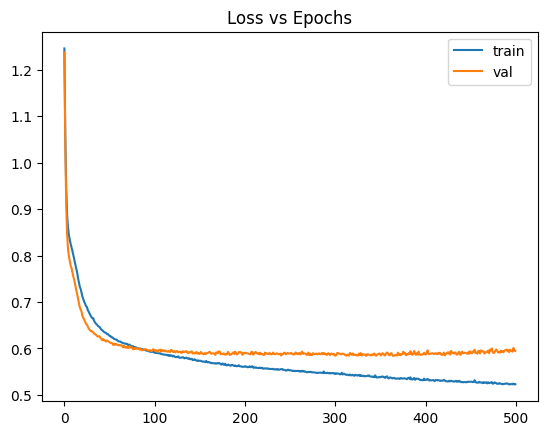

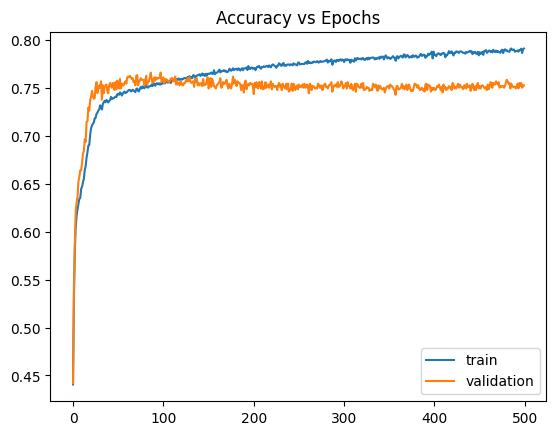

In [ ]:
epochs_range = range(n_epochs)

plt.figure()
plt.plot(epochs_range, history["train_loss"], label="train")
plt.plot(epochs_range, history["val_loss"], label="val")
plt.legend()
plt.title("Loss vs Epochs")
plt.show()

plt.figure()
plt.plot(epochs_range, history["train_acc"], label="train")
plt.plot(epochs_range, history["val_acc"], label="validation")
plt.legend()
plt.title("Accuracy vs Epochs")
plt.show()

Training loss keeps dropping, but validation loss bottoms out and starts climbing after roughly 120 epochs — this model is starting to memorize the training set rather than generalize. That's the entire value of tracking both curves throughout training, not just training loss on its own.

**Industry connection:** this is exactly the plot an ML engineer pulls up first when a model's live performance doesn't match its offline evaluation — is it genuinely the wrong model, or did it simply overfit past a checkpoint nobody saved?

---
### QUIZ 6

**Training loss keeps decreasing across all 500 epochs, but validation loss starts rising after epoch ~120. What should you conclude?**

a) The learning rate is too low, and training just needs more epochs to converge properly.

b) The model is overfitting after epoch ~120 — it's starting to memorize training data rather than generalize.

c) There's a bug in the `DataLoader` causing validation data to leak into training.

d) The batch size is too large and should be reduced to fix the divergence.

**Correct answer: b**

A training loss that keeps falling while validation loss rises is the textbook overfitting signature — the model is fitting noise specific to the training set rather than the underlying pattern. Options (a), (c), and (d) each propose a fix aimed at a different symptom than the one actually observed here; none of them address a widening train/val gap directly.

---

## Recap

- `nn.Linear` / `nn.Sequential` build a model layer by layer, with every shape stated explicitly
- Weight initialization sets exactly where training starts from — Kaiming is PyTorch's default, Xavier/Glorot is a common alternative
- Loss function and optimizer are two separate, explicit objects — nothing hidden behind a single setup call
- Training is a loop you write and fully control: `zero_grad → forward → loss → backward → step`, repeated per batch, per epoch
- Tracking history is just choosing what to record, epoch by epoch, in a plain dictionary

**Bridge to Part 2:** today's model was one input, one output, strictly sequential. Next session: what happens when a model needs to branch — multiple inputs, multiple outputs — and how do you correctly evaluate and monitor a model once it's trained?

**Reflection prompt (chat):** in one sentence — what's the biggest difference between how you *thought* a neural network trains, and what you just watched happen in the loop above?